# PPH/CIG analysis verification on 80-km equal-area cells (CSV output)

This notebook verifies Chris's practically-perfect hindcast (PPH) / CIG analyses **as if they were forecasts**, the same way `do_verf_outlooks_tiles.ipynb` verifies the SPC outlooks. Only the reading of the files differs:
- The PPH files hold three properties: `hazard`, `level` (cig0–cig3) and `probability`.
- There is no valid time, issue time or forecaster in the files.
- There is nothing to download.

Everything else is the same as the outlook notebook, so the output files have the same columns and the analysis code can be shared:
- the Storm Events handling;
- the 80-km cells in EPSG:5070;
- the (probability, CIG) forecast categories;
- the cumulative 40-km observation footprints;
- the CSV files and the scores.

**Start with the 1630 files:** `{YYYYMMDD}1630.geojson`, 3 Mar – 30 Jun 2026.

**Things to keep in mind when reading the results** (more in the last cell):
- **The valid window is assumed** to be 16:30Z on the file's date to 12Z the next day. Section 6 checks this against the reports.
- **The reports may come from a different source.** The PPH were presumably built from reports, maybe not Storm Events. Differences between the two report sets show up here as forecast errors.
- **These are hindcasts.** The CIG areas were drawn around the significant reports, so their conditional statistics are good by construction, not by skill.

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import requests
import matplotlib.pyplot as plt

## Settings

In [2]:
DATES    = pd.date_range('2026-03-03', '2026-06-30', freq='D')    # convective days
HHMM     = '1630'                                                  # which PPH analysis time to verify

CRS_EQ   = 'EPSG:5070'        # NAD83 / CONUS Albers: equal-area, meters
CELL_M   = 80_000.0           # cell size (m)
BUFFER_M = 40_000.0           # report footprint radius (m)
GRID     = 1.0                # snap overlay results to a 1-m grid (section 3)

# hazard -> PPH folder, Storm Events type, thresholds (lowest = "any report"), column labels
HAZARDS = {
    'torn': dict(folder='tornado', event_type='Tornado',           thresholds=[0, 1, 2, 3, 4],
                 labels=['ef0', 'ef1', 'ef2', 'ef3', 'ef4']),
    'wind': dict(folder='wind',    event_type='Thunderstorm Wind', thresholds=[50, 56, 65, 74, 83],
                 labels=['50kt', '56kt', '65kt', '74kt', '83kt']),
    'hail': dict(folder='hail',    event_type='Hail',              thresholds=[1.0, 1.5, 2.0, 3.5],
                 labels=['1p0in', '1p5in', '2p0in', '3p5in']),
}

DATA     = os.path.expanduser('~/Downloads/PPH_geojsons')
USA_FILE = f'{DATA}/usa_outline.geojson'
REG_FILE = f'{DATA}/bukovsky_regions_groups.geojson'
PPH_DIR  = DATA                                        # with tornado/, wind/, hail/ subfolders
OUT_DIR  = os.path.expanduser('~/datasets/pph_tiles_2026')
# Storm Events from NCEI: https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/ (check for the latest c-date)
STORM_EVENTS = os.path.expanduser('~/datasets/storm_events/StormEvents_details-ftp_v1.0_d2026_c20261119.csv.gz')   # local copy; the URL also works
os.makedirs(OUT_DIR, exist_ok=True)

def pph_path(day, haz):
    return os.path.join(PPH_DIR, HAZARDS[haz]['folder'], f'{day:%Y%m%d}{HHMM}.geojson')

def pph_window(day):
    # ASSUMED valid window of an HHMM file: HHMM on its date to 12Z the next day (checked in section 6)
    return (day + pd.Timedelta(hours=int(HHMM[:2]), minutes=int(HHMM[2:])),
            day + pd.Timedelta(days=1, hours=12))

## 2. Storm Events reports

Storm Events times are local standard time, and `CZ_TIMEZONE` gives the offset: `CST-6` means UTC = local + 6 h. The offset is read from the string itself, so every zone is handled; your original cells dropped MST-7. Anything that can't be parsed is counted and reported.

The magnitude `mag` is the EF rating for tornadoes (EFU = 0), knots for wind, and inches for hail. Events below the lowest threshold, or with no magnitude, are left out and counted.

In [3]:
def tz_offset_hours(tz):
    # Hours to ADD to Storm Events local time to get UTC: 'CST-6' -> 6, 'AKST-9' -> 9, 'GST10' -> -10
    m = re.fullmatch(r'([A-Za-z]+)(-?)(\d+)', str(tz).strip())
    if m is None:
        return np.nan
    n = float(m.group(3))
    return n if m.group(2) == '-' else -n

EF = {'EFU': 0, 'EF0': 0, 'EF1': 1, 'EF2': 2, 'EF3': 3, 'EF4': 4, 'EF5': 5}

def storm_events_table(storm, haz):
    spec = HAZARDS[haz]
    d = storm[storm.EVENT_TYPE == spec['event_type']].copy()
    off_h = d.CZ_TIMEZONE.map(tz_offset_hours)
    off = pd.to_timedelta(off_h, unit='h')
    d['t0'] = pd.to_datetime(d.BEGIN_DATE_TIME, format='%d-%b-%y %H:%M:%S') + off
    d['t1'] = pd.to_datetime(d.END_DATE_TIME,   format='%d-%b-%y %H:%M:%S') + off
    d['lon0'], d['lat0'] = d.BEGIN_LON, d.BEGIN_LAT
    d['lon1'], d['lat1'] = d.END_LON.fillna(d.BEGIN_LON), d.END_LAT.fillna(d.BEGIN_LAT)
    d['mag'] = d.TOR_F_SCALE.map(EF) if haz == 'torn' else pd.to_numeric(d.MAGNITUDE, errors='coerce')
    bad_t = d.t1 < d.t0
    d.loc[bad_t, 't1'] = d.loc[bad_t, 't0']
    no_tz, no_loc = off_h.isna(), d.lat0.isna() | d.lon0.isna()
    below = ~(d.mag >= spec['thresholds'][0])            # also True when mag is missing
    print(f"{haz}: {len(d)} events | time zones {d.CZ_TIMEZONE.value_counts().to_dict()}")
    print(f"   dropped: {no_tz.sum()} unparseable time zone, {no_loc.sum()} no location, "
          f"{below.sum()} below {spec['thresholds'][0]} or no magnitude; {bad_t.sum()} had end before begin")
    keep = ~no_tz & ~no_loc & ~below
    return d.loc[keep, ['EVENT_ID', 'mag', 'MAGNITUDE_TYPE', 'TOR_F_SCALE',
                        't0', 't1', 'lon0', 'lat0', 'lon1', 'lat1']].reset_index(drop=True)

storm = pd.read_csv(STORM_EVENTS, low_memory=False)
REPORTS = {haz: storm_events_table(storm, haz) for haz in HAZARDS}
for haz, r in REPORTS.items():
    print(haz, 'magnitudes:', r.mag.value_counts().sort_index().to_dict() if haz == 'torn'
          else r.mag.describe()[['min', '50%', 'max']].to_dict())

torn: 1394 events | time zones {'CST-6': 1007, 'EST-5': 328, 'MST-7': 58, 'PST-8': 1}
   dropped: 0 unparseable time zone, 0 no location, 0 below 0 or no magnitude; 0 had end before begin
wind: 22419 events | time zones {'EST-5': 10790, 'CST-6': 9287, 'MST-7': 2191, 'PST-8': 139, 'AST-4': 11, 'SST-11': 1}
   dropped: 0 unparseable time zone, 0 no location, 1064 below 50 or no magnitude; 0 had end before begin
hail: 7512 events | time zones {'CST-6': 5426, 'EST-5': 1068, 'MST-7': 989, 'PST-8': 27, 'AST-4': 2}
   dropped: 0 unparseable time zone, 0 no location, 818 below 1.0 or no magnitude; 0 had end before begin
torn magnitudes: {0: 705, 1: 595, 2: 71, 3: 22, 4: 1}
wind magnitudes: {'min': 50.0, '50%': 52.0, 'max': 114.0}
hail magnitudes: {'min': 1.0, '50%': 1.25, 'max': 6.6}


## 3. Domain, cells, and the geometry helpers

**Cells:** squares on a fixed 80-km lattice. A cell's id is `i_j`, where i = floor(x / 80 km) and j = floor(y / 80 km) in EPSG:5070, so an id always means the same square. Edge cells are clipped to the US outline. Each cell is assigned to the Bukovsky regions (and region groups) that contain a point inside it.

**Precision:** every intersection, union and difference is snapped to a 1-m grid (`grid_size=GRID`), as `set_precision(1.)` did in your original code. Without it, floating-point overlay occasionally counted a band twice inside a cell; that happened in 3 of about 178,000 cases in testing.

In [4]:
def to_eq(g):
    return (g if g.crs else g.set_crs(4326)).to_crs(CRS_EQ)

usa = to_eq(gpd.read_file(USA_FILE))
domain = shapely.set_precision(shapely.make_valid(usa.union_all()), GRID)

def make_cells(domain, cell_m):
    minx, miny, maxx, maxy = domain.bounds
    i_rng = np.arange(np.floor(minx / cell_m), np.ceil(maxx / cell_m)).astype(int)
    j_rng = np.arange(np.floor(miny / cell_m), np.ceil(maxy / cell_m)).astype(int)
    ii, jj = [a.ravel() for a in np.meshgrid(i_rng, j_rng)]
    boxes = shapely.box(ii * cell_m, jj * cell_m, (ii + 1) * cell_m, (jj + 1) * cell_m)
    g = gpd.GeoDataFrame({'cell_id': [f'{i}_{j}' for i, j in zip(ii, jj)], 'i': ii, 'j': jj,
                          'x_center': (ii + 0.5) * cell_m, 'y_center': (jj + 0.5) * cell_m},
                         geometry=shapely.intersection(boxes, domain, grid_size=GRID), crs=CRS_EQ)
    g = g[~g.is_empty & (g.area > 0)].reset_index(drop=True)
    g['area_km2'] = g.area / 1e6
    ll = gpd.GeoSeries(gpd.points_from_xy(g.x_center, g.y_center), crs=CRS_EQ).to_crs(4326)
    g['lon'], g['lat'] = ll.x.values, ll.y.values
    return g

cells = make_cells(domain, CELL_M)
regions = to_eq(gpd.read_file(REG_FILE))
pts = cells[['cell_id']].set_geometry(cells.representative_point())
cell_regions = (gpd.sjoin(pts, regions[['names', 'group', 'geometry']], predicate='within')
                [['cell_id', 'names', 'group']].rename(columns={'names': 'region'}))
print(f'{len(cells)} cells covering {cells.area_km2.sum():,.0f} km2 (domain {domain.area/1e6:,.0f} km2)')

def polygonal(g):
    # Keep only the area parts of a geometry. Two polygons that touch along an edge can intersect
    # in a line; shapely refuses to mix lines and polygons in later steps.
    if g.is_empty or g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    parts = [p for p in shapely.get_parts(g) if p.geom_type in ('Polygon', 'MultiPolygon')]
    return shapely.union_all(parts, grid_size=GRID) if parts else shapely.Polygon()

def union(geoms):
    return polygonal(shapely.union_all(geoms, grid_size=GRID)) if geoms else shapely.Polygon()

def clean(geom):
    return polygonal(shapely.set_precision(shapely.make_valid(geom), GRID))

def overlay(fn, a, b):
    # intersection or difference on a 1-m grid, keeping only polygon parts
    return polygonal(fn(a, b, grid_size=GRID))

1456 cells covering 8,499,419 km2 (domain 8,499,419 km2)


## 4. PPH file to forecast categories

This is the main difference from the outlook notebook. In the PPH files:
- `level = 'cig0'` features are the probability contours; `probability` is the coverage in percent. Wind goes up to 75% and 90%, which the SPC outlooks never use.
- `level = 'cig1'`, `'cig2'`, `'cig3'` features are the CIG areas. Their `probability` is a fixed number for each level (tornado CIG1 = 2, CIG2 = 5; wind 5/10/15; hail 5/7.5), not a forecast, so it is ignored.
- An empty file (no features) becomes 0% with no CIG everywhere. That can mean no reports, or a processing problem. Section 6 lists empty files on days that had reports.

`bands` and `categories` are the same functions as in the outlook notebook:
- "At or above L" is the union of every polygon at or above L, so it works whether the contours are stored as full areas or as rings.
- A location's CIG is the highest CIG drawn over it.
- Every location in the domain falls in exactly one (probability, CIG) category.

In [5]:
def read_pph(path, day):
    g = to_eq(gpd.read_file(path))
    prob, cig, unknown = {}, {}, []
    for _, r in g.iterrows():
        if r.geometry is None or r.geometry.is_empty:
            continue
        lev = str(r['level']).strip().lower()
        if lev == 'cig0':
            prob.setdefault(float(r['probability']), []).append(clean(r.geometry))
        elif re.fullmatch(r'cig[1-9]', lev):
            cig.setdefault(int(lev[3:]), []).append(clean(r.geometry))
        else:
            unknown.append(lev)
    if unknown:
        print(f'   WARNING {os.path.basename(path)}: unrecognized levels {unknown}')
    valid, expire = pph_window(day)
    return dict(valid=valid, expire=expire, n_features=len(g), prob_polys=prob, cig_polys=cig)

def bands(polys, domain):
    # {level: [polygons]} -> {level: exclusive band}, including level 0 = rest of the domain
    levels = sorted(set(polys) | {0})
    ge = {L: overlay(shapely.intersection, union([p for k, ps in polys.items() if k >= L for p in ps]), domain)
          for L in levels[1:]}
    ge[0] = domain
    out = {}
    for k, L in enumerate(levels):
        above = ge[levels[k + 1]] if k + 1 < len(levels) else shapely.Polygon()
        b = overlay(shapely.difference, ge[L], above)
        if not b.is_empty:
            out[L] = b
    return out

def categories(fc, domain):
    # GeoDataFrame with one row per (prob, cig) combination present in the outlook
    pb, cb = bands(fc['prob_polys'], domain), bands(fc['cig_polys'], domain)
    rows = []
    for p, pg in pb.items():
        for c, cg in cb.items():
            g = overlay(shapely.intersection, pg, cg)
            if not g.is_empty and g.area > 0:
                rows.append((p, c, g))
    return gpd.GeoDataFrame(rows, columns=['prob', 'cig', 'geometry'], crs=CRS_EQ)

## 5. Reports to footprints, and categories to cell pieces

`reports_in_window` keeps the part of each report inside the analysis's (assumed) valid window. A track that starts at 16:10Z is cut at its 16:30Z position for a 1630 file, by linear interpolation along the track (the same assumption as the hourly splitting in your notebook). Points are kept if they fall in the window.

`footprints` buffers those pieces by 40 km and unions them **once per threshold**, using every report at or above that threshold. The footprints are nested: the EF2+ footprint lies inside the EF1+ footprint.

`tile_rows` cuts each category along the cell edges. `cells.sindex.query` finds the cells a category touches, so only those are intersected. Each piece becomes one row with its area and the area of each footprint inside it.

`report_categories` records, for each report piece, the highest probability and the highest CIG it touches. For a track, these are taken separately along its length, so the two can come from different spots on the track.

In [6]:
def reports_in_window(ev, t_start, t_end):
    is_point = (ev.t1 <= ev.t0).to_numpy()
    keep = np.where(is_point, (ev.t0 >= t_start) & (ev.t0 < t_end), (ev.t0 < t_end) & (ev.t1 > t_start))
    e = ev[keep].copy()
    if e.empty:
        return gpd.GeoDataFrame(e, geometry=[], crs=4326)
    dur = (e.t1 - e.t0).dt.total_seconds().to_numpy()
    ta = e.t0.where(e.t0 > t_start, t_start)             # clip the start of the track to the window
    tb = e.t1.where(e.t1 < t_end, t_end)                 # clip the end
    safe = np.where(dur > 0, dur, 1.0)
    wa = np.where(dur > 0, (ta - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    wb = np.where(dur > 0, (tb - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    e['lon_a'], e['lat_a'] = e.lon0 + wa * (e.lon1 - e.lon0), e.lat0 + wa * (e.lat1 - e.lat0)
    e['lon_b'], e['lat_b'] = e.lon0 + wb * (e.lon1 - e.lon0), e.lat0 + wb * (e.lat1 - e.lat0)
    geoms = [shapely.Point(a, b) if (a == c and b == d) else shapely.LineString([(a, b), (c, d)])
             for a, b, c, d in zip(e.lon_a, e.lat_a, e.lon_b, e.lat_b)]
    return gpd.GeoDataFrame(e, geometry=geoms, crs=4326)

def footprints(rep, haz, domain):
    # {label: area within BUFFER_M of any report with mag >= threshold}
    spec = HAZARDS[haz]
    disks = rep.to_crs(CRS_EQ).buffer(BUFFER_M) if len(rep) else gpd.GeoSeries([], crs=CRS_EQ)
    out = {}
    for thr, lab in zip(spec['thresholds'], spec['labels']):
        sel = disks[(rep.mag >= thr).to_numpy()].values if len(rep) else []
        out[lab] = overlay(shapely.intersection, union(list(sel)), domain)
    return out

def tile_rows(cats, fps, cells):
    cell_geom, cell_ids = cells.geometry.values, cells.cell_id.values
    parts = []
    for p, c, cat in cats[['prob', 'cig', 'geometry']].itertuples(index=False):
        idx = cells.sindex.query(cat, predicate='intersects')            # cells this category touches
        pieces = np.array([polygonal(p) for p in shapely.intersection(cell_geom[idx], cat, grid_size=GRID)])
        df = pd.DataFrame({'cell_id': cell_ids[idx], 'prob': p, 'cig': c,
                           'area_km2': shapely.area(pieces) / 1e6})
        for lab, fp in fps.items():
            df[f'obs_{lab}'] = (0.0 if fp.is_empty else
                                shapely.area(shapely.intersection(pieces, fp, grid_size=GRID)) / 1e6)
        parts.append(df)
    out = pd.concat(parts, ignore_index=True)
    return out[out.area_km2 > 1e-6]

def report_categories(rep, cats):
    r = rep.to_crs(CRS_EQ)[['EVENT_ID', 'mag', 't0', 't1', 'lon_a', 'lat_a', 'lon_b', 'lat_b', 'geometry']]
    j = gpd.sjoin(r, cats[['prob', 'cig', 'geometry']], how='left', predicate='intersects')
    best = j.groupby(level=0)[['prob', 'cig']].max()                  # NaN = outside the domain
    return r.drop(columns='geometry').join(best)

## 6. Check the valid-window assumption, then run and write the CSV files

The files carry no times, so this first cell tests the assumed window against the reports. If the 1630 PPH were built from reports between 16:30Z and 12Z:
- nearly every report piece in that window should fall inside the PPH area (the lowest probability contour);
- a wider window (12–12Z) should add reports that fall outside the PPH.

Agreement won't be perfect if the PPH used a different report source. The cell also lists two kinds of mismatch day:
- an empty PPH file on a day with reports;
- a PPH on a day with no reports in the window.

In [7]:
H0 = int(HHMM[:2]) + int(HHMM[2:]) / 60                       # the file's assumed start, hours after 00Z
ASSUMED = f'{HHMM}-12Z (assumed)'
WINDOWS = {ASSUMED: (H0, 36), '12-12Z': (12, 36), '1630-12Z': (16.5, 36), '1630-00Z': (16.5, 24)}   # hours after 00Z on the day
WINDOWS = dict(list({k: v for k, v in WINDOWS.items() if k == ASSUMED or v != (H0, 36)}.items()))   # no duplicate of the assumed one

def window_check(haz):
    rows = []
    for day in DATES:
        path = pph_path(day, haz)
        if not os.path.exists(path):
            continue
        fc = read_pph(path, day)
        area = union([p for ps in fc['prob_polys'].values() for p in ps])
        for name, (h0, h1) in WINDOWS.items():
            rep = reports_in_window(REPORTS[haz], day + pd.Timedelta(hours=h0), day + pd.Timedelta(hours=h1))
            n = len(rep)
            n_in = 0 if (n == 0 or area.is_empty) else int(shapely.intersects(rep.to_crs(CRS_EQ).geometry.values, area).sum())
            rows.append((day.date(), name, n, n_in, not area.is_empty))
    return pd.DataFrame(rows, columns=['date', 'window', 'n_reports', 'n_inside_pph', 'pph_nonempty'])

for haz in HAZARDS:
    wc = window_check(haz)
    s = wc.groupby('window')[['n_reports', 'n_inside_pph']].sum()
    s['share_inside'] = s.n_inside_pph / s.n_reports
    print(f'\n=== {haz}: report pieces inside the PPH area, by window ===')
    display(s)
    a = wc[wc.window == ASSUMED]
    print('empty PPH but reports in the window:', a.loc[~a.pph_nonempty & (a.n_reports > 0), ['date', 'n_reports']].values.tolist())
    print('PPH drawn but no reports in the window:', a.loc[a.pph_nonempty & (a.n_reports == 0), 'date'].astype(str).tolist())


=== torn: report pieces inside the PPH area, by window ===


,n_reports,n_inside_pph,share_inside
window,,,
12-12Z,1085,1040,0.958525
1630-00Z,413,405,0.980630
1630-12Z (assumed),1025,1016,0.991220


empty PPH but reports in the window: [[datetime.date(2026, 4, 11), 5]]
PPH drawn but no reports in the window: ['2026-06-03']



=== wind: report pieces inside the PPH area, by window ===


,n_reports,n_inside_pph,share_inside
window,,,
12-12Z,11511,11109,0.965077
1630-00Z,5688,5587,0.982243
1630-12Z (assumed),10936,10753,0.983266


empty PPH but reports in the window: [[datetime.date(2026, 3, 8), 3], [datetime.date(2026, 4, 11), 62], [datetime.date(2026, 4, 30), 1], [datetime.date(2026, 5, 10), 47]]
PPH drawn but no reports in the window: []



=== hail: report pieces inside the PPH area, by window ===


,n_reports,n_inside_pph,share_inside
window,,,
12-12Z,5190,4975,0.958574
1630-00Z,3078,2990,0.971410
1630-12Z (assumed),4991,4874,0.976558


empty PPH but reports in the window: [[datetime.date(2026, 4, 11), 7], [datetime.date(2026, 5, 10), 73]]
PPH drawn but no reports in the window: ['2026-03-14']


Four files per hazard go to `OUT_DIR`, with the same columns as the outlook notebook so the analysis code works on both:

| File | One row per | Main columns |
| --- | --- | --- |
| `cells.csv`, `cell_regions.csv` | cell (and cell–region pair) | cell_id, lon, lat, area_km2; region, group |
| `analyses_{haz}.csv` | PPH file (day) | status, assumed valid window, max_prob, max_cig, area at or above each probability level, area of each CIG level, report counts |
| `tiles_{haz}.csv` | day × cell × probability × CIG piece | area_km2, obs_* (footprint area at or above each threshold) |
| `reports_{haz}.csv` | report piece inside the window | EVENT_ID, mag, times, clipped positions, prob and cig at the report |

In [8]:
cells.drop(columns='geometry').to_csv(f'{OUT_DIR}/cells.csv', index=False)
cell_regions.to_csv(f'{OUT_DIR}/cell_regions.csv', index=False)

def analysis_summary(fc, cats, rep, haz):
    s = dict(valid=fc['valid'], expire=fc['expire'], n_features=fc['n_features'],
             max_prob=max(fc['prob_polys'], default=0), max_cig=max(fc['cig_polys'], default=0))
    for L in sorted(cats.prob.unique()):
        if L > 0:
            s[f'area_ge{L:g}_km2'] = cats.loc[cats.prob >= L].area.sum() / 1e6
    for k in sorted(cats.cig.unique()):
        if k > 0:
            s[f'area_cig{k}_km2'] = cats.loc[cats.cig == k].area.sum() / 1e6
    for thr, lab in zip(HAZARDS[haz]['thresholds'], HAZARDS[haz]['labels']):
        s[f'n_rep_{lab}'] = int((rep.mag >= thr).sum())
    return s

t_begin = time.time()
for haz in HAZARDS:
    summ, tiles, reps = [], [], []
    for day in DATES:
        path = pph_path(day, haz)
        row = dict(date=day.date(), hazard=haz, file=os.path.basename(path))
        if not os.path.exists(path):
            summ.append({**row, 'status': 'missing'}); continue
        fc = read_pph(path, day)
        cats = categories(fc, domain)
        rep = reports_in_window(REPORTS[haz], fc['valid'], fc['expire'])
        tr = tile_rows(cats, footprints(rep, haz, domain), cells)
        tr.insert(0, 'date', day.date())
        tiles.append(tr)
        if len(rep):
            rc = report_categories(rep, cats)
            rc.insert(0, 'date', day.date())
            reps.append(rc)
        status = 'risk' if fc['prob_polys'] else ('empty file' if fc['n_features'] == 0 else 'no risk')
        summ.append({**row, 'status': status, **analysis_summary(fc, cats, rep, haz)})
    pd.DataFrame(summ).to_csv(f'{OUT_DIR}/analyses_{haz}.csv', index=False)
    if tiles:
        pd.concat(tiles, ignore_index=True).to_csv(f'{OUT_DIR}/tiles_{haz}.csv', index=False)
    if reps:
        pd.concat(reps, ignore_index=True).to_csv(f'{OUT_DIR}/reports_{haz}.csv', index=False)
    print(f'{haz}: {len(tiles)} analyses scored, {sum(len(t) for t in tiles):,} tile rows, '
          f'{sum(len(r) for r in reps):,} report pieces ({time.time() - t_begin:.0f} s)')

torn: 120 analyses scored, 182,400 tile rows, 1,025 report pieces (6 s)


wind: 120 analyses scored, 192,368 tile rows, 10,936 report pieces (17 s)


hail: 120 analyses scored, 185,582 tile rows, 4,991 report pieces (25 s)


## 7. Reading the output

Everything below uses only the CSV files, so it can run in a fresh session. It is the same code as in the outlook notebook; only the file name `analyses_{haz}.csv` differs.

First, a check: on each day, the pieces of a cell must add up to the cell's area, and the footprints must be nested (an EF2+ area can't be bigger than the EF1+ area).

In [9]:
haz = 'torn'
labs = HAZARDS[haz]['labels']
obs = [f'obs_{l}' for l in labs]
cells_df = pd.read_csv(f'{OUT_DIR}/cells.csv')
ol = pd.read_csv(f'{OUT_DIR}/analyses_{haz}.csv', parse_dates=['date'])
t  = pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date'])
rp = pd.read_csv(f'{OUT_DIR}/reports_{haz}.csv', parse_dates=['date'])

chk = t.groupby(['date', 'cell_id']).area_km2.sum().reset_index().merge(cells_df[['cell_id', 'area_km2']],
                                                                        on='cell_id', suffixes=('', '_cell'))
err = (chk.area_km2 - chk.area_km2_cell).abs() / chk.area_km2_cell
print(f'piece areas vs cell area: max relative error {err.max():.1e}, cells off by >0.1%: {(err > 1e-3).sum()}')
excess = max((t[b] - t[a]).max() for a, b in zip(obs[:-1], obs[1:]))
print(f'footprints nested (higher threshold never larger): largest excess {excess:.4f} km2 '
      f'(anything under ~0.01 km2 is 1-m grid rounding)')
print(ol.status.value_counts().to_dict())

piece areas vs cell area: max relative error 5.3e-04, cells off by >0.1%: 0
footprints nested (higher threshold never larger): largest excess 0.0050 km2 (anything under ~0.01 km2 is 1-m grid rounding)
{'risk': 80, 'empty file': 40}


### General characteristics of the PPH/CIG analyses

max_cig,0,1,2,All
max_prob,,,,
0.0,40,0,0,40
2.0,1,0,0,1
5.0,36,1,0,37
10.0,17,2,0,19
15.0,2,5,4,11
30.0,3,2,3,8
45.0,0,1,1,2
60.0,0,0,2,2
All,99,11,10,120


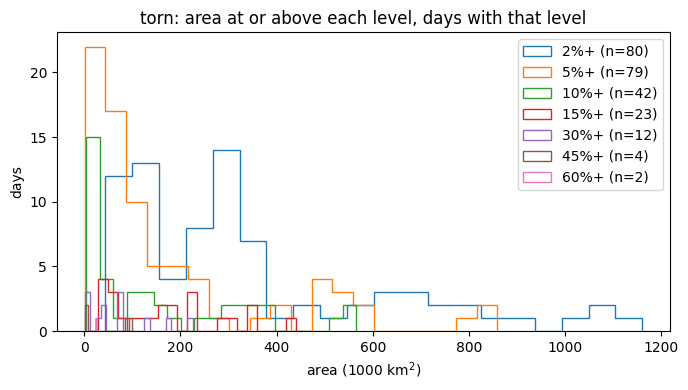

In [10]:
ok = ol[ol.status != 'missing']
display(pd.crosstab(ok.max_prob, ok.max_cig, margins=True))          # highest level drawn, per day

area_cols = [c for c in ok.columns if c.startswith('area_ge')]
fig, ax = plt.subplots(figsize=(7, 4))
for c in area_cols:
    v = ok[c].dropna()
    if len(v):
        ax.hist(v / 1e3, bins=20, histtype='step', label=f"{c[7:-4]}%+ (n={len(v)})")
ax.set(xlabel='area (1000 km$^2$)', ylabel='days', title=f'{haz}: area at or above each level, days with that level')
ax.legend(); plt.tight_layout(); plt.show()

### Conditional and unconditional intensity by forecast category

Within a category:
- **Unconditional:** P(report ≥ threshold within 40 km) = obs / area.
- **Conditional on a report occurring:** P(≥ threshold | any report within 40 km) = obs / obs at the lowest threshold.

Both are pooled over all days, so they are area-weighted. The last line puts confidence intervals on the conditional fractions by resampling whole days.

In [11]:
g = t.groupby(['prob', 'cig'])[['area_km2'] + obs].sum()
g['n_days'] = t.groupby(['prob', 'cig']).date.nunique()
uncond = g[obs].div(g.area_km2, axis=0)
cond   = g[obs].div(g[obs[0]], axis=0)
display(g[['n_days', 'area_km2']].round(0))
display(uncond.round(4))
display(cond.round(3))

def boot_cond(t, num, den, n_boot=1000, seed=0):
    # 90% interval for sum(num)/sum(den) per category, resampling whole days
    rng = np.random.default_rng(seed)
    daily = t.groupby(['prob', 'cig', 'date'])[[num, den]].sum()
    out = {}
    for key, d in daily.groupby(level=[0, 1]):
        x, y = d[num].to_numpy(), d[den].to_numpy()
        idx = rng.integers(0, len(x), (n_boot, len(x)))
        with np.errstate(invalid='ignore', divide='ignore'):
            r = x[idx].sum(1) / y[idx].sum(1)
        out[key] = np.nanpercentile(r, [5, 95]) if np.isfinite(r).any() else [np.nan, np.nan]
    return pd.DataFrame(out, index=['p05', 'p95']).T

display(boot_cond(t, 'obs_ef2', 'obs_ef0').round(3))   # e.g. P(EF2+ | tornado) with 90% intervals

n_days     area_km2
prob cig                     
0.0  0       120  992191286.0
2.0  0        80   13153923.0
     1        16     622785.0
5.0  0        78    6252492.0
     1        19    1173722.0
     2         3      20088.0
10.0 0        40    1677240.0
     1        18     868558.0
     2         7      76012.0
15.0 0        17    1453686.0
     1        18    1231894.0
     2        10     329819.0
30.0 0         8     300275.0
     1         8     262945.0
     2         4     120654.0
45.0 0         1       6605.0
     1         3      79402.0
     2         1      59224.0
60.0 1         1      25606.0
     2         1      24074.0

obs_ef0  obs_ef1  obs_ef2  obs_ef3  obs_ef4
prob cig                                             
0.0  0     0.0000   0.0000   0.0000   0.0000   0.0000
2.0  0     0.0109   0.0012   0.0000   0.0000   0.0000
     1     0.0096   0.0096   0.0096   0.0000   0.0000
5.0  0     0.0884   0.0299   0.0000   0.0000   0.0000
     1     0.0262   0.0252   0.0220   0.0000   0.0000
     2     0.0572   0.0000   0.0000   0.0000   0.0000
10.0 0     0.1704   0.0794   0.0000   0.0000   0.0000
     1     0.0656   0.0364   0.0100   0.0001   0.0001
     2     0.2009   0.1784   0.1321   0.0885   0.0100
15.0 0     0.2914   0.1938   0.0000   0.0000   0.0000
     1     0.2907   0.2029   0.0812   0.0007   0.0000
     2     0.3760   0.3517   0.2286   0.1656   0.0158
30.0 0     0.6204   0.4312   0.0000   0.0000   0.0000
     1     0.5377   0.3425   0.0735   0.0000   0.0000
     2     0.5392   0.3794   0.2425   0.1336   0.0000
45.0 0     1.0000   0.6536   0.0000   0.0000   0.0000
     1     0.7276   0.5964   0.2158   0.0000   0.0000
     2     0.8122   0.6889   0.3127   0.1543   0.0000
60.0 1     0.8999   0.8791   0.2019   0.0000   0.0000
     2     0.9989   0.9687   0.4405   0.3692   0.0000

obs_ef0  obs_ef1  obs_ef2  obs_ef3  obs_ef4
prob cig                                             
0.0  0        1.0    0.263    0.000    0.000    0.000
2.0  0        1.0    0.109    0.000    0.000    0.000
     1        1.0    1.000    1.000    0.000    0.000
5.0  0        1.0    0.339    0.000    0.000    0.000
     1        1.0    0.961    0.842    0.000    0.000
     2        1.0    0.000    0.000    0.000    0.000
10.0 0        1.0    0.466    0.000    0.000    0.000
     1        1.0    0.554    0.152    0.001    0.001
     2        1.0    0.888    0.658    0.441    0.050
15.0 0        1.0    0.665    0.000    0.000    0.000
     1        1.0    0.698    0.279    0.002    0.000
     2        1.0    0.935    0.608    0.441    0.042
30.0 0        1.0    0.695    0.000    0.000    0.000
     1        1.0    0.637    0.137    0.000    0.000
     2        1.0    0.704    0.450    0.248    0.000
45.0 0        1.0    0.654    0.000    0.000    0.000
     1        1.0    0.820    0.297    0.000    0.000
     2        1.0    0.848    0.385    0.190    0.000
60.0 1        1.0    0.977    0.224    0.000    0.000
     2        1.0    0.970    0.441    0.370    0.000

p05    p95
0.0  0  0.000  0.000
2.0  0  0.000  0.000
     1  0.999  1.000
5.0  0  0.000  0.000
     1  0.619  0.998
     2  0.000  0.000
10.0 0  0.000  0.000
     1  0.065  0.230
     2  0.165  0.766
15.0 0  0.000  0.000
     1  0.185  0.358
     2  0.470  0.737
30.0 0  0.000  0.000
     1  0.052  0.307
     2  0.100  0.689
45.0 0  0.000  0.000
     1  0.123  0.315
     2  0.385  0.385
60.0 1  0.224  0.224
     2  0.441  0.441

In [12]:
# Report-count version: ratings of the reports, by the highest category each report touched
display(pd.crosstab([rp.prob, rp.cig], rp.mag, margins=True))

mag         0    1   2   3  4   All
prob cig                           
0.0  0      6    3   0   0  0     9
2.0  0      7    2   0   0  0     9
     1      0    0   1   0  0     1
5.0  0    119   42   0   0  0   161
     1      1    1   5   0  0     7
10.0 0     57   32   0   0  0    89
     1      5    3   1   0  0     9
     2      1    1   1   1  0     4
15.0 0     82  101   0   0  0   183
     1     61   54  19   0  0   134
     2     22   28   7  10  1    68
30.0 0     49   67   0   0  0   116
     1     30   32   5   0  0    67
     2     11   13   6   3  0    33
45.0 0     11    3   0   0  0    14
     1      9   28   5   0  0    42
     2      6   18   2   4  0    30
60.0 1      3   18   2   0  0    23
     2     15    7   1   3  0    26
All       495  453  55  21  1  1025

In [13]:
# Calibration of the coverage probabilities (any report), from the same columns
cov = t.groupby('prob')[['area_km2', obs[0]]].sum()
cov['obs_freq'] = cov[obs[0]] / cov.area_km2
display(cov)
f, A, O = cov.index / 100, cov.area_km2, cov[obs[0]]
obar = O.sum() / A.sum()
bs = ((f**2) * A - 2 * f * O + O).sum() / A.sum()
print(f'BS = {bs:.5f}, BSS vs sample climatology = {1 - bs / (obar * (1 - obar)):.4f}')

,area_km2,obs_ef0,obs_freq
prob,,,
0.0,9.921913e+08,39105.803896,0.000039
2.0,1.377671e+07,149900.650836,0.010881
5.0,7.446302e+06,584359.024907,0.078476
10.0,2.621810e+06,358076.595594,0.136576
15.0,3.015400e+06,905736.355711,0.300370
30.0,6.838738e+05,392730.627533,0.574274
45.0,1.452314e+05,112482.368899,0.774504
60.0,4.967946e+04,47088.540155,0.947847


BS = 0.00198, BSS vs sample climatology = 0.2197


## 8. Verification scores from the tile output

Every common score can be built from sums of `area_km2` and the `obs_*` columns, for any subset of rows (a day, a month, a region, a forecast category). For a piece with forecast probability f, area A, and observed area O (the part within 40 km of a report):

- **Squared error** over the piece: f²·A − 2·f·O + O. Summed and divided by the total area, this gives the Brier score.
- **Contingency table** at a threshold p (forecast "yes" where f ≥ p):
    - hits = O where f ≥ p
    - false alarms = A − O where f ≥ p
    - misses = O where f < p
    - correct nulls = A − O where f < p

    POD, FAR, SR, CSI, frequency bias, POFD and HSS follow from these four areas.
- **ROC curve:** POD against POFD as the threshold steps down through the probability levels. AUC is the area under it.

`level_table` sums the areas for each forecast value, optionally within groups. The score functions then work on that small table.

In [14]:
def level_table(t, obs_col, fcol='prob', area_col='area_km2', by=None):
    # Sum area and observed area for each forecast value (optionally within groups `by`)
    keys = (by or []) + [fcol]
    g = t.groupby(keys)[[area_col, obs_col]].sum().reset_index()
    return g.rename(columns={fcol: 'fcst', area_col: 'A', obs_col: 'O'})

def div(a, b):
    return a / b if b > 0 else np.nan

def prob_scores(lt):
    # Brier score and decomposition, BSS against the sample climatology, ROC area. fcst in percent.
    f, A, O = lt.fcst.to_numpy() / 100, lt.A.to_numpy(), lt.O.to_numpy()
    N, n_obs = A.sum(), O.sum()
    obar = n_obs / N
    bs = (f**2 * A - 2 * f * O + O).sum() / N
    oj = np.divide(O, A, out=np.full(len(O), np.nan), where=A > 0)
    rel = np.nansum(A * (f - oj)**2) / N
    res = np.nansum(A * (oj - obar)**2) / N
    unc = obar * (1 - obar)
    order = np.argsort(-f)                                   # highest probability first
    pod = np.r_[0, np.cumsum(O[order]) / n_obs] if n_obs > 0 else np.full(len(f) + 1, np.nan)
    pofd = np.r_[0, np.cumsum((A - O)[order]) / (N - n_obs)]
    auc = np.sum(np.diff(pofd) * (pod[1:] + pod[:-1]) / 2)
    return pd.Series(dict(BS=bs, BSS=div(unc - bs, unc), REL=rel, RES=res, UNC=unc,
                          obs_freq=obar, mean_fcst=(f * A).sum() / N, AUC=auc, area_km2=N))

def contingency(lt):
    # One row per threshold: forecast "yes" where fcst >= threshold
    A, O = lt.A.sum(), lt.O.sum()
    rows = []
    for p in sorted(lt.fcst.unique())[1:]:                   # the lowest value is never a "yes"
        yes = lt.fcst >= p
        a, b = lt.O[yes].sum(), (lt.A - lt.O)[yes].sum()     # hits, false alarms
        c, d = O - a, (A - O) - b                            # misses, correct nulls
        n = a + b + c + d
        expected = ((a + b) * (a + c) + (c + d) * (b + d)) / n
        rows.append(dict(threshold=p, hits=a, false_alarms=b, misses=c, correct_nulls=d,
                         POD=div(a, a + c), FAR=div(b, a + b), SR=div(a, a + b), CSI=div(a, a + b + c),
                         bias=div(a + b, a + c), POFD=div(b, b + d), HSS=div(a + d - expected, n - expected)))
    return pd.DataFrame(rows)

In [15]:
# Coverage probabilities verified against any report, for each hazard
for haz, spec in HAZARDS.items():
    th = pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date'])
    lt = level_table(th, f"obs_{spec['labels'][0]}")
    print(f'\n=== {haz}: probabilities vs any report (>= {spec["thresholds"][0]}) ===')
    display(prob_scores(lt).round(5).to_frame().T)
    display(contingency(lt).round(4))


=== torn: probabilities vs any report (>= 0) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.00198,0.21973,0.00015,0.00071,0.00253,0.00254,0.00163,0.98843,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,2.0,2.550374e+06,2.518863e+07,3.910580e+04,9.921522e+08,0.9849,0.9081,0.0919,0.0918,10.7122,0.0248,0.1643
1,5.0,2.400474e+06,1.156182e+07,1.890065e+05,1.005779e+09,0.9270,0.8281,0.1719,0.1696,5.3919,0.0114,0.2870
2,10.0,1.816114e+06,4.699879e+06,7.733655e+05,1.012641e+09,0.7013,0.7213,0.2787,0.2491,2.5163,0.0046,0.3967
3,15.0,1.458038e+06,2.436146e+06,1.131442e+06,1.014905e+09,0.5631,0.6256,0.3744,0.2901,1.5038,0.0024,0.4481
4,30.0,5.523015e+05,3.264831e+05,2.037178e+06,1.017014e+09,0.2133,0.3715,0.6285,0.1894,0.3394,0.0003,0.3176
5,45.0,1.595709e+05,3.533995e+04,2.429909e+06,1.017305e+09,0.0616,0.1813,0.8187,0.0608,0.0753,0.0000,0.1143
6,60.0,4.708854e+04,2.590919e+03,2.542391e+06,1.017338e+09,0.0182,0.0522,0.9478,0.0182,0.0192,0.0000,0.0356



=== wind: probabilities vs any report (>= 50) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.01103,0.34868,0.00092,0.00683,0.01694,0.01723,0.01088,0.96848,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,5.0,1.693622e+07,6.544756e+07,6.394861e+05,9.369070e+08,0.9636,0.7944,0.2056,0.2040,4.6874,0.0653,0.3195
1,15.0,1.394482e+07,2.116805e+07,3.630891e+06,9.811865e+08,0.7934,0.6029,0.3971,0.3599,1.9978,0.0211,0.5183
2,30.0,8.658185e+06,5.148330e+06,8.917525e+06,9.972062e+08,0.4926,0.3729,0.6271,0.3810,0.7855,0.0051,0.5449
3,45.0,4.727664e+06,1.225787e+06,1.284805e+07,1.001129e+09,0.2690,0.2059,0.7941,0.2515,0.3387,0.0012,0.3966
4,60.0,2.201941e+06,2.730020e+05,1.537377e+07,1.002082e+09,0.1253,0.1103,0.8897,0.1234,0.1408,0.0003,0.2163
5,75.0,7.981290e+05,5.697205e+04,1.677758e+07,1.002298e+09,0.0454,0.0666,0.9334,0.0453,0.0487,0.0001,0.0851
6,90.0,1.788082e+03,0.000000e+00,1.757392e+07,1.002355e+09,0.0001,0.0000,1.0000,0.0001,0.0001,0.0000,0.0002



=== hail: probabilities vs any report (>= 1.0) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.00603,0.2511,0.00043,0.00245,0.00805,0.00811,0.00497,0.96575,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,5.0,7.875098e+06,4.211888e+07,3.997955e+05,9.695365e+08,0.9517,0.8425,0.1575,0.1563,6.0416,0.0416,0.2600
1,15.0,5.873709e+06,1.123507e+07,2.401184e+06,1.000420e+09,0.7098,0.6567,0.3433,0.3011,2.0676,0.0111,0.4569
2,30.0,2.781492e+06,1.936659e+06,5.493401e+06,1.009719e+09,0.3361,0.4105,0.5895,0.2724,0.5702,0.0019,0.4248
3,45.0,7.125170e+05,2.329607e+05,7.562376e+06,1.011422e+09,0.0861,0.2464,0.7536,0.0837,0.1143,0.0002,0.1531
4,60.0,7.862949e+04,9.912318e+03,8.196264e+06,1.011645e+09,0.0095,0.1120,0.8880,0.0095,0.0107,0.0000,0.0186


In [16]:
# The same functions on subsets: by month, by region, and day by day (tornado)
t['month'] = t.date.dt.to_period('M')
by_month = level_table(t, 'obs_ef0', by=['month']).groupby('month').apply(prob_scores, include_groups=False)
display(by_month[['BS', 'BSS', 'REL', 'RES', 'AUC', 'obs_freq']].round(4))

reg = pd.read_csv(f'{OUT_DIR}/cell_regions.csv')
tr = t.merge(reg[['cell_id', 'region']], on='cell_id')          # a cell can be in a region and its group
by_region = level_table(tr, 'obs_ef0', by=['region']).groupby('region').apply(prob_scores, include_groups=False)
display(by_region[['BS', 'BSS', 'AUC', 'obs_freq', 'area_km2']].round(4))

daily = level_table(t, 'obs_ef0', by=['date']).groupby('date').apply(prob_scores, include_groups=False)
daily_ct = (level_table(t, 'obs_ef0', by=['date']).groupby('date').apply(contingency, include_groups=False)
            .reset_index(level=0))
display(daily_ct[daily_ct.threshold == 5][['date', 'POD', 'SR', 'CSI', 'bias']].head())

,BS,BSS,REL,RES,AUC,obs_freq
month,,,,,,
2026-03,0.0016,0.2354,0.0001,0.0006,0.9975,0.0021
2026-04,0.0025,0.2283,0.0002,0.0010,0.9832,0.0032
2026-05,0.0012,0.1889,0.0001,0.0004,0.9969,0.0014
2026-06,0.0027,0.2153,0.0002,0.0010,0.9833,0.0035


,BS,BSS,AUC,obs_freq,area_km2
region,,,,,
Appalachia,0.0029,0.2173,0.9952,0.0038,5.760000e+07
CENTRAL,0.0035,0.2481,0.9902,0.0047,3.097937e+08
CONUS,0.0020,0.2197,0.9884,0.0025,1.019930e+09
CPlains,0.0031,0.1087,0.9768,0.0035,5.913600e+07
DeepSouth,0.0038,0.1632,0.9906,0.0046,6.528000e+07
EAST,0.0022,0.1998,0.9835,0.0027,2.083430e+08
GreatBasin,0.0000,NaN,NaN,0.0000,8.256505e+07
GreatLakes,0.0033,0.2150,0.9725,0.0042,6.185934e+07
Mezquital,0.0006,0.0512,0.9009,0.0006,3.970960e+07


,date,POD,SR,CSI,bias
1,2026-03-05,1.000000,0.140823,0.140823,7.101104
1,2026-03-06,1.000000,0.148023,0.148023,6.755695
1,2026-03-08,0.340366,1.000000,0.340366,0.340366
1,2026-03-09,1.000000,0.207258,0.207258,4.824904
1,2026-03-10,0.946889,0.167434,0.165876,5.655308


### Scoring the CIG levels

A CIG level isn't a probability, so it doesn't get a Brier score, but the same tools apply **given that a report occurred**. Replace the area with the "any report" footprint and the observed area with the footprint at a higher threshold:

- forecast "yes" = CIG ≥ k;
- event = a report at or above the threshold (e.g. EF2+) within 40 km;
- the sample = the area within 40 km of any report.

A hit is then area near an EF2+ tornado inside CIG ≥ k. A false alarm is area near tornadoes, all weaker than EF2, inside CIG ≥ k. POD, SR and CSI measure whether the CIG areas pick out where the stronger tornadoes happened, among places that had tornadoes.

In [17]:
# Conditional contingency: did CIG >= k separate EF2+ (EF3+) tornado area from weaker tornado area?
for thr in ['obs_ef2', 'obs_ef3']:
    lt = level_table(t, thr, fcol='cig', area_col='obs_ef0')
    print(f'CIG vs {thr}, given any tornado within 40 km')
    display(contingency(lt).round(3))

CIG vs obs_ef2, given any tornado within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,326070.391,625480.092,0.00,1637929.484,1.000,0.657,0.343,0.343,2.918,0.276,0.397
1,2,143840.222,133803.247,182230.17,2129606.329,0.441,0.482,0.518,0.313,0.851,0.059,0.408


CIG vs obs_ef3, given any tornado within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,96367.326,855183.157,0.000,1637929.484,1.000,0.899,0.101,0.101,9.874,0.343,0.125
1,2,95506.731,182136.738,860.595,2310975.904,0.991,0.656,0.344,0.343,2.881,0.073,0.482


## 9. Conditional distribution of intensity within each CIG level

These charts are modeled on the ones on SPC's outlook page. For each CIG level, the question is: given a report within 40 km, how is the **strongest** nearby report distributed across the intensity classes?

**Area-based version** (top row), computed from `tiles_{haz}.csv`:
- The `obs_*` columns are cumulative ("at or above"). Subtracting neighboring columns gives exclusive classes. For example, obs_ef1 − obs_ef2 is the area whose strongest tornado within 40 km was EF1.
- Within a CIG level, each class's area is divided by the area within 40 km of any report (`obs` at the lowest threshold). The bars for a CIG level therefore add up to 100%.
- This is the point-wise definition the outlook probabilities use.
- The probability levels are pooled within each CIG level. `<CIG1` includes every area without a CIG, also the 0% area.
- Whiskers are 90% intervals from resampling whole days.

**Report-count version** (bottom row), computed from `reports_{haz}.csv`: the share of reports in each class, using the highest CIG each report touched. A day with 50 reports counts 50 times here, while in the area version clustered reports overlap and count once.

Rounding can make a difference of cumulative columns slightly negative (about 0.01 km² at most); those values are set to zero.

**SPC reference (diamonds):** the distributions shown on SPC's outlook page (https://www.spc.noaa.gov/about/outlooks/), typed in from the chart labels on 24 Nov 2026 (`SPC_REF`). How SPC computed them (period, report counts or area, radius) is not stated in the numbers here, so compare shapes rather than reading small differences as meaningful.

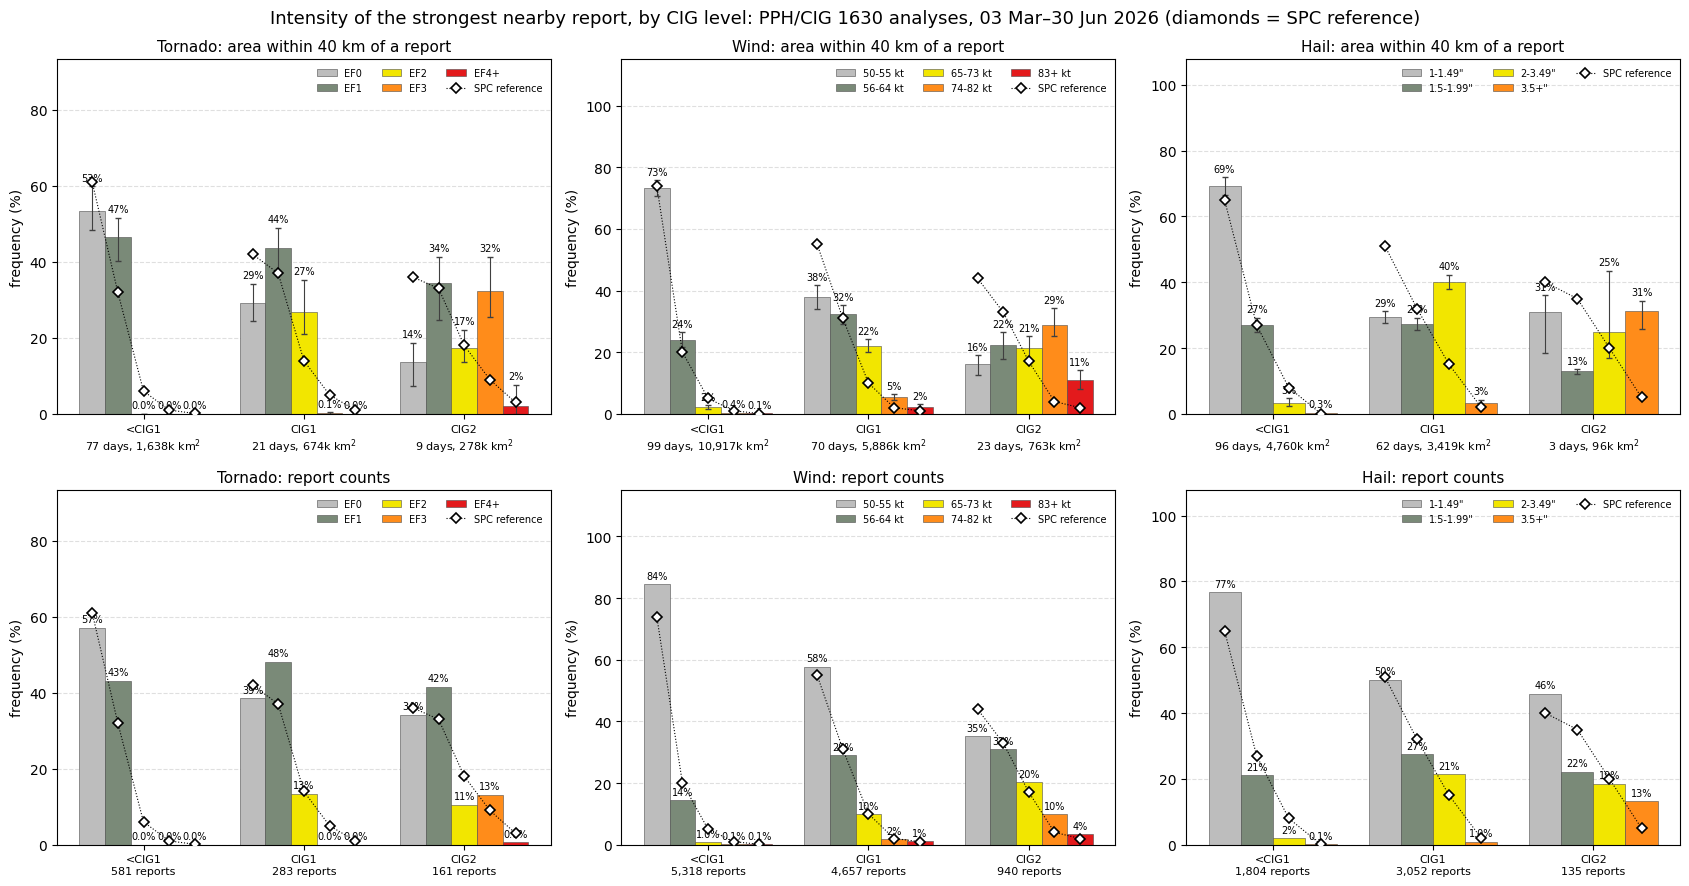

torn


cls,EF0,EF1,EF2,EF3,EF4+,n_days
cig,,,,,,
0,53.5,46.5,0.0,0.0,0.0,77
1,29.2,43.7,26.9,0.1,0.0,21
2,13.8,34.4,17.4,32.2,2.1,9


wind


cls,50-55 kt,56-64 kt,65-73 kt,74-82 kt,83+ kt,n_days
cig,,,,,,
0,73.3,24.0,2.2,0.4,0.1,99
1,37.9,32.3,22.1,5.4,2.3,70
2,16.1,22.3,21.5,29.0,11.1,23


hail


cls,"1-1.49""","1.5-1.99""","2-3.49""","3.5+""",n_days
cig,,,,,
0,69.4,27.0,3.4,0.3,96
1,29.3,27.3,40.0,3.4,62
2,30.9,13.1,24.8,31.2,3


In [18]:
CLASS_NAMES = {'torn': ['EF0', 'EF1', 'EF2', 'EF3', 'EF4+'],
               'wind': ['50-55 kt', '56-64 kt', '65-73 kt', '74-82 kt', '83+ kt'],
               'hail': ['1-1.49"', '1.5-1.99"', '2-3.49"', '3.5+"']}
CLASS_COLORS = ['#bdbdbd', '#7a8a78', '#f2e600', '#ff8c1a', '#e31a1c']
CIG_LEVELS = [0, 1, 2]                      # CIG3 is too rare in this sample (one wind area)
CIG_NAMES = {0: '<CIG1', 1: 'CIG1', 2: 'CIG2', 3: 'CIG3'}

def intensity_by_cig(t, haz, n_boot=1000, seed=0):
    # Area-based: share of the "any report within 40 km" area whose strongest nearby report is in each class
    obs = [f'obs_{l}' for l in HAZARDS[haz]['labels']]
    daily = t[t.cig.isin(CIG_LEVELS)].groupby(['cig', 'date'])[obs].sum()
    nxt = daily[obs].shift(-1, axis=1).fillna(0.0)          # the next-higher threshold (0 after the last)
    excl = (daily[obs] - nxt).clip(lower=0)
    excl.columns = CLASS_NAMES[haz]
    rng = np.random.default_rng(seed)
    rows = []
    for c, d in excl.groupby(level='cig'):
        tot = d.sum(axis=1).to_numpy()                       # = obs at the lowest threshold, per day
        x = d.to_numpy()
        share = x.sum(0) / tot.sum() if tot.sum() > 0 else np.full(x.shape[1], np.nan)
        idx = rng.integers(0, len(x), (n_boot, len(x)))
        with np.errstate(invalid='ignore', divide='ignore'):
            boot = x[idx].sum(1) / tot[idx].sum(1)[:, None]
        lo, hi = np.nanpercentile(boot, [5, 95], axis=0)
        for k, name in enumerate(excl.columns):
            rows.append(dict(cig=c, cls=name, share=share[k], lo=lo[k], hi=hi[k],
                             n_days=int((tot > 0).sum()), any_area_km2=tot.sum()))
    return pd.DataFrame(rows)

def intensity_by_cig_counts(rp, haz):
    # Report-count: share of report pieces in each class, by the highest CIG each report touched
    thr = HAZARDS[haz]['thresholds']
    r = rp[rp.cig.isin(CIG_LEVELS)].copy()
    r['cls'] = np.array(CLASS_NAMES[haz])[np.digitize(r.mag, thr) - 1]
    ct = pd.crosstab(r.cig, r.cls).reindex(columns=CLASS_NAMES[haz], fill_value=0)
    out = ct.div(ct.sum(axis=1), axis=0).stack().rename('share').reset_index()
    out['n_reports'] = out.cig.map(ct.sum(axis=1))
    return out

def bar_panel(ax, df, haz, whiskers=True, note_col=None):
    names, ncls = CLASS_NAMES[haz], len(CLASS_NAMES[haz])
    width = 0.8 / ncls
    for k, name in enumerate(names):
        d = df[df.cls == name].set_index('cig').reindex(CIG_LEVELS)
        x = np.arange(len(CIG_LEVELS)) + (k - (ncls - 1) / 2) * width
        ax.bar(x, 100 * d.share, width, color=CLASS_COLORS[k], edgecolor='0.3', lw=0.4, label=name)
        if whiskers and 'lo' in d:
            ax.errorbar(x, 100 * d.share, yerr=[100 * (d.share - d.lo), 100 * (d.hi - d.share)],
                        fmt='none', ecolor='0.25', lw=0.8, capsize=2)
        tops = d.hi if (whiskers and 'hi' in d) else d.share          # put labels above the whiskers
        for xi, v, tp in zip(x, d.share, tops):
            if np.isfinite(v):
                ax.text(xi, 100 * max(v, tp) + 1, f'{100 * v:.0f}%' if v >= 0.01 else f'{100 * v:.1f}%',
                        ha='center', va='bottom', fontsize=7)
    labels = []
    for c in CIG_LEVELS:
        d = df[df.cig == c]
        extra = ''
        if note_col == 'area' and len(d):
            extra = f"\n{d.n_days.iloc[0]} days, {d.any_area_km2.iloc[0] / 1e3:,.0f}k km$^2$"
        elif note_col == 'count' and len(d):
            extra = f"\n{d.n_reports.iloc[0]:,} reports"
        labels.append(CIG_NAMES[c] + extra)
    ax.set_xticks(np.arange(len(CIG_LEVELS)), labels, fontsize=8)
    ax.set_ylabel('frequency (%)'); ax.grid(axis='y', ls='--', alpha=0.4); ax.set_axisbelow(True)
    ax.legend(fontsize=7, ncol=ncls, loc='upper right', frameon=False)

# SPC reference distributions: intensity of reports by CIG level, typed in from the chart labels on
# https://www.spc.noaa.gov/about/outlooks/ (24 Nov 2026). Percent in each class; each row adds to ~100 (rounding).
SPC_REF = {
    'torn': {0: [61, 32, 6, 1, 0.1], 1: [42, 37, 14, 5, 1], 2: [36, 33, 18, 9, 3], 3: [31, 28, 22, 14, 5]},
    'wind': {0: [74, 20, 5, 1, 0.1], 1: [55, 31, 10, 2, 1], 2: [44, 33, 17, 4, 2], 3: [33, 34, 23, 7, 4]},
    'hail': {0: [65, 27, 8, 0.1],    1: [51, 32, 15, 2],    2: [40, 35, 20, 5]},
}

def ref_overlay(ax, haz, ref=SPC_REF):
    # SPC's reference value on top of each bar: a black diamond, joined by a thin line within each CIG level
    from matplotlib.lines import Line2D
    ncls = len(CLASS_NAMES[haz]); width = 0.8 / ncls
    for i, c in enumerate(CIG_LEVELS):
        if c not in ref.get(haz, {}):
            continue
        x = i + (np.arange(ncls) - (ncls - 1) / 2) * width
        ax.plot(x, ref[haz][c], color='k', lw=0.8, ls=':', marker='D', ms=5, mfc='white', mec='k', mew=1.2, zorder=5)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], color='k', lw=0.8, ls=':', marker='D', ms=5, mfc='white', mec='k', mew=1.2))
    labels.append('SPC reference')
    ax.legend(handles, labels, fontsize=7, ncol=3, loc='upper right', frameon=False)
    top = max(max(v) for v in ref.get(haz, {}).values())
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, max(hi, top * 1.3 + 14))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
dist_area, dist_count = {}, {}
for j, (haz, title) in enumerate([('torn', 'Tornado'), ('wind', 'Wind'), ('hail', 'Hail')]):
    th = pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date'])
    rp = pd.read_csv(f'{OUT_DIR}/reports_{haz}.csv', parse_dates=['date'])
    dist_area[haz], dist_count[haz] = intensity_by_cig(th, haz), intensity_by_cig_counts(rp, haz)
    bar_panel(axes[0, j], dist_area[haz], haz, note_col='area')
    bar_panel(axes[1, j], dist_count[haz], haz, whiskers=False, note_col='count')
    axes[0, j].set_title(f'{title}: area within 40 km of a report', fontsize=11)
    axes[1, j].set_title(f'{title}: report counts', fontsize=11)
    top = 100 * max(dist_area[haz].hi.max(), dist_count[haz].share.max())
    for ax in axes[:, j]:
        ax.set_ylim(0, min(115, top * 1.3 + 8))       # headroom for the legend
        ref_overlay(ax, haz)                          # SPC's reference distribution
fig.suptitle(f'Intensity of the strongest nearby report, by CIG level: PPH/CIG {HHMM} analyses, '
             f'{DATES[0]:%d %b}–{DATES[-1]:%d %b %Y} (diamonds = SPC reference)', fontsize=13)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/intensity_by_cig_{HHMM}.png', dpi=130)
plt.show()

# the numbers behind the top row (percent of the area within 40 km of any report)
for haz, d in dist_area.items():
    print(haz)
    display(d.pivot(index='cig', columns='cls', values='share')[CLASS_NAMES[haz]].mul(100).round(1)
             .assign(n_days=d.groupby('cig').n_days.first()))

## Notes

**Differences from `do_verf_outlooks_tiles.ipynb`:**
- Section 1 (download) is gone.
- Section 4 reads `level` and `probability` instead of `LABEL`.
- Section 6 adds the window check.
- The per-file summary has no issue time or forecaster.

The output columns are the same, so the two runs can be compared directly. For example:
- merge `tiles_torn.csv` from both output folders on `date` and `cell_id`;
- or compare `level_table` results side by side.

**Caveats for interpreting PPH scores**
- **Valid window.** Assumed to be 16:30Z to 12Z. Check section 6 before trusting the scores. If a different window fits the reports better, change `pph_window`.
- **Report source.** If the PPH weren't built from Storm Events, any difference between report sets is scored as a forecast error. That happens through timing, locations, or reports added or dropped later in Storm Data. In the 12Z files (10 Nov notes) there were 5% tornado PPH days with no Storm Events tornado in the window.
- **By construction.** The CIG polygons were drawn around the significant reports. In the 12Z files, tornado CIG1 contained 98% of EF2+ report points. Conditional statistics within CIG will therefore look very good. That measures how the analysis was built, not skill.
- **Scale.** The PPH probabilities come from smoothing the reports, and they are verified here with a 40-km footprint. Agreement depends partly on how close the smoothing scale is to 40 km.
- **Significant wind.** The thresholds here are SPC's (65 kt is one of them). The 12Z analysis suggested Chris used 65 kt (75 mph) for significant wind.